In [1]:
import os
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import astropy
from astropy.io import fits
from astropy.visualization import ImageNormalize, AsinhStretch, LinearStretch, LogStretch, MinMaxInterval, PercentileInterval, AsymmetricPercentileInterval, make_lupton_rgb
from astropy.stats import sigma_clipped_stats, SigmaClip
from astropy.convolution import Gaussian2DKernel, convolve

from photutils.background import Background2D, MedianBackground
from photutils.segmentation import detect_sources, detect_threshold

import skimage as ski
from skimage.segmentation import inverse_gaussian_gradient, morphological_geodesic_active_contour
from skimage.measure import regionprops, shannon_entropy
from skimage.restoration import inpaint_biharmonic

from scipy import ndimage
from scipy.stats import skew
from scipy.ndimage import gaussian_filter, binary_dilation


# Cambios a nivel de lógica:

## I. AUDITORÍA CRÍTICA DE TU PROPUESTA ESTADÍSTICA
Tu intuición es correcta en el objetivo: quieres rescatar las estructuras de muy baja señal (filamentos, escombros de marea, halos difusos). Pero la métrica matemática que propones luz = np.median + 2 * np.std aplicada directamente sobre la imagen normalizada RGB tiene tres problemas graves:
1. La **Paradoja de la Normalización**: Si aplicas un algoritmo de normalización (como un escalado lineal Min-Max o un percentil), estás *forzando artificialmente* a que los píxeles caigan en un rango fijo (por ejemplo, [0.0, 1.0]). Por ende, calcular la mediana y la desviación estándar de la matriz ya normalizada ***no te dirá cuánta luz real rescataste, sino qué tan homogéneamente distribuyó los valores ese algoritmo específico***.
2. El **Impuesto Hormiga"** del Fondo del Cielo: En una **imagen astronómica, el 80% o 90% de los píxeles corresponden a espacio profundo** (ruido de fondo). Por lo tanto, ***np.median(imagen) y np.std(imagen)*** van a estar dominados casi en su totalidad por el ***universo vacío***, no por la galaxia. La luz de los *filamentos tenues quedará completamente ahogada en la estadística global*.
3. **Saturación del Núcleo**: Los algoritmos lineales expanden el ruido y saturan el núcleo hiperbrillante, volviendo invisibles las estructuras helicoidales internas. Necesitamos ***curvas asintóticas***.

## II. PROPUESTA METODOLÓGICA CORRECTA: ANÁLISIS DE RANGO DINÁMICO DE SEÑAL (SDR):
Para sustentar científicamente ante el comité cuál normalización expone la mayor cantidad de estructuras difusas sin romper el núcleo, debes realizar el análisis sobre la matriz de datos físicos crudos (Image - Background) y evaluar cómo cada función de estiramiento (Stretch) transforma los histogramas. En lugar de una sola métrica plana, debes graficar y **comparar tres técnicas no lineales** que la comunidad astrofísica avala (contenidas en la librería astropy.visualization):
1. **AsinhStretch (Seno hiperbólico inverso)**: Es la regla de oro para *filamentos. Mapea de forma logarítmica los flujos bajos (levantando los escombros de marea del ruido) y de forma lineal los flujos altos (protegiendo el núcleo)*.
2. **LogStretch (Estiramiento Logarítmico)**: Excelente para ver el *halo exterior*, pero suele ***saturar el bulbo central de la galaxia perdiendo la estructura de Concentración (C)***.
3. **LinearStretch con AsymmetricPercentileInterval**: Tu *métrica de control*. Demostrará cómo el contraste lineal deja los ***filamentos en la absoluta obscuridad***.

## III. Demostración matemática - "cómo se distribuye o degrada la luz":
El análisis correcto es ***graficar la Función de Distribución Acumulada (CDF)*** o el ***Histograma de Frecuencias de Intensidad*** *en la región de la galaxia para cada normalización*.
La **normalización ganadora** ***será aquella que muestre una mayor densidad de píxeles (un "bulto" o skewness positivo) en los rangos intermedios de intensidad (ej. de 0.1 a 0.4 en la escala normalizada)***, lo que prueba físicamente que los filamentos salieron del fondo negro y ahora ocupan un rango dinámico útil para los kernels de la Attention UNet.



## Pipeline Adaptativo del Bloque 0 - Arquitectura Definitiva
**Proyecto Integrador / Tesis de Maestría en IA Aplicada**  
**Dataset:** DESI Legacy Imaging Survey (DR10) - Cubos de Datos FITS de 4 Canales `[g, r, i, z]` (1600 × 1600 píxeles)  
**Target de Modelado:** Attention UNet (Feature Cube Multicanal)

### 1. `metricas_fondo(cubo_original)`
* **Operación:** Modelado y estimación de la neblina del cielo astronómico parásito para cada banda de forma independiente utilizando `Background2D`.
* **Física/Estadística:** Determina el nivel base del cielo y la desviación estándar del grano fotográfico (`std_u`) por canal. No elimina el ruido estocástico, calibra el nivel de la neblina.
* **Retorno:** `arreglos_limpios` (matrices crudas - fondo local por canal), `bkg_canales` (mapas de fondo) y estadísticas de `sigma_clipped_stats` por canal.

### 2. `metricas_colapsada(arreglos_limpios)`
* **Operación:** Fusión matricial de las 4 bandas mediante combinación lineal óptima utilizando `np.mean(axis=0)`.
* **Física/Estadística:** Genera la matriz multibanda cruda (`glx_mc`). Por propagación de errores, el colapso reduce estadísticamente la varianza del ruido de fondo. Se extraen las métricas de ruido exclusivas de esta matriz colapsada para evitar desfases numéricos posteriores.
* **Retorno:** Matriz colapsada `glx_mc` y estadísticas específicas del fondo colapsado (`background_rms` y mediana).

### 3. Normalización Temporal (Control Geométrico Rápido)
* **Operación:** Aplicación de un estiramiento asintótico base y rápido (ej. `AsinhStretch` estándar combinado con un `PercentileInterval(1, 99)`) sobre `glx_mc`.
* **Física/Estadística:** Su único fin es geométrico. Despega el contraste de la galaxia del espacio profundo para permitir la segmentación ciega de la estructura completa sin importar la saturación física del núcleo.
* **Retorno:** Matriz colapsada con contraste temporal expandido.

### 4. `mascara_gaussiana(multibanda_normalizada_temporal)`
* **Operación:** Convolución espacial con un kernel gaussiano (`Gaussian2DKernel`) y umbralización automática adaptativa mediante `detect_sources` y `SourceCatalog`.
* **Física/Estadística:** Aplica el criterio de Área Máxima para seleccionar programáticamente el ID del segmento principal. Esta silueta (dilatada morfológicamente) es nuestro "Escudo Protector Universal" binario.
* **Retorno:** `bm_galaxia` (máscara maestra) y `seg_gauss`.

### 5. Normalización y Spline Definitivo
* **Operación:** Aplicación rigurosa de los hiperparámetros óptimos ganadores del Grid Search (Paso 5) sobre la matriz `glx_aislada_cruda`.
* **Física/Estadística:** Comprime de forma no lineal los flujos crudos purificados en la escala definitiva de entrenamiento `[0.0, 1.0]`. Estabiliza el spline del contorno activo (`active_contour`) liberando la presión numérica interna del arreglo para calcar la geometría exterior de forma plástica.
* **Retorno:** Matriz normalizada definitiva y contornos suavizados estables.

# Extracción de datos RAW

In [56]:
gname = 'NGC5576_215.2651_3.2708.fits'
fits_path = Path.cwd()/Path('Imagenes-Test/NGC5576_215.2651_3.2708.fits')#FITS\1-115357_grz.fits
#open fits file
hdulist= fits.open(fits_path)
hdulist.info()
headers = fits.getheader(fits_path)
image_data= fits.getdata(fits_path)
hdulist.close()
    

Filename: c:\Users\jfmag\OneDrive\Documentos\Maestria\Proyecto integrador\Imagenes-Test\NGC5576_215.2651_3.2708.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      29   (2000, 2000, 4)   float32   


In [57]:
headers

SIMPLE  =                    T / file does conform to FITS standard             
BITPIX  =                  -32 / number of bits per data pixel                  
NAXIS   =                    3 / number of data axes                            
NAXIS1  =                 2000 / length of data axis 1                          
NAXIS2  =                 2000 / length of data axis 2                          
NAXIS3  =                    4 / length of data axis 3                          
EXTEND  =                    T / FITS dataset may contain extensions            
COMMENT   FITS (Flexible Image Transport System) format is defined in 'Astronomy
COMMENT   and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H 
SURVEY  = 'LegacySurvey'                                                        
VERSION = 'DR10    '                                                            
IMAGETYP= 'IMAGE   '           / None                                           
BANDS   = 'griz    '        

In [59]:
headers['BANDS']

'griz'

In [28]:
image_data.shape

(4, 3000, 3000)

## Obtención de imagen RAW a color

**Diferencias para el color:**
- Asignación de Filtros:
    - image_r = Banda i (Infrarrojo cercano medio) o Banda z
	- image_g = Banda r (Rojo óptico)
	- image_b = Banda g (Verde/Azul óptico)
- Tabla analítica para la combinación de canales:

|Combinación de Canales [r, g, b] |Información Física Dominante|Estructura que Rescata Mejor|Riesgo Algorítmico|Física de la galaxia expuesta|Ventaja principal|
|-------------|-------------|-------------|-------------|-------------|-------------|
|Óptica [i, r, g]|Poblaciones estelares jóvenes y emisión de gas ionizado.|Brazos espirales externos y cúmulos de formación estelar.|El polvo interestelar bloquea la luz y puede crear "hoyos" falsos.| La **banda g resalta los cúmulos de estrellas masivas tipo O y B (muy calientes)**. La **banda r** captura la emisión del **gas hidrógeno ionizado (Hα), que rastrea directamente la Tasa de Formación Estelar (SFR)** actual.|Resalta Suavidad/Grumosidad (C)
|Infrarroja [z, i, r]|Poblaciones estelares viejas de larga vida (Masa pura).|Núcleo galáctico, bulbos densos y filamentos de marea fríos.|Puede subestimar las plumas de marea calientes periféricas.|  Esqueleto de **Masa Estelar M***: Las **bandas i y z** son casi insensibles a las estrellas jóvenes transitorias; **registran la luz de las gigantes rojas y estrellas enanas viejas que componen el 90% de la masa real de la galaxia**. Estructuras dinámicas estables: Revela la verdadera **morfología del bulbo central y puentes gravitacionales**.| Concentración (C) y el indicador D4000
|Híbrida (Matriz de mezcla)|Balance espectral completo (fusión de energía multi-banda).|Continuidad morfológica global del sistema interactuante.|Si no se calibran los pesos, una banda brillante (como la z) puede opacar a las otras.|El **Gradiente de Población Estelar (De dentro hacia fuera)**: Expone de forma cruda el **mecanismo de crecimiento de las galaxias (Inside-Out growth)**. Verás transiciones matemáticas perfectas desde un *núcleo altamente concentrado, viejo y metalizado en la banda z, transitando por regiones de gas ionizado en r, hasta la periferia difusa y joven en g*. **Zonas de Interacción Dinámica (Filamentos y Puentes)**: Los escombros de marea y filamentos que tanto te interesa rescatar tienen firmas multibanda muy específicas. Al ser gas arrancado gravitacionalmente, suele enfriarse y brillar débilmente en el infrarrojo, pero puede encender brotes de formación estelar al colisionar, brillando en el azul. Solo la multibanda captura este comportamiento dual.|Sistema CAS Completo e Historia Evolutiva (SFH).|

***Hibridación correcta de las matrices - Multibanda colapsada***
- Lo correcto para obtener la máscara es colapsar los canales **utilizando un promedio ponderado** o aplicar la función mascara_gaussiana sobre la matriz de intensidad de Lupton (que ya normaliza y estira los rangos dinámicos de forma asintótica antes de la umbralización).
- Dos formas:
    - relación señal-ruido (SNR) ó Matriz de Intensidad Escalada (I) que propone el propio Lupton (2004):
    1. Lógica Estadística: combinación lineal donde cada banda se divide primero por su nivel de calibración o su respuesta de fondo para homologar las unidades físicas.
    2. La Operación: Se define la intensidad píxel a píxel como el promedio de los flujos de los canales una vez sustraído su respectivo cielo

        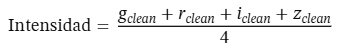

    3. El Secreto para la Máscara: A esa matriz de intensidad promedio se le aplica la función de estiramiento hiperbólico inverso (AsinhStretch). Al hacerlo, las regiones tenues de la banda g (brazos) y las estructuras densas de la banda z (núcleo) se nivelan en el mismo rango dinámico.
    - la respuesta del flujo físico ó combinación por varianza mínima:
    1. Cálculo de Pesos: Utilizas los valores de la desviación estándar del fondo corregida que ya obtienes con éxito en tu función metricas_fondo para cada canal individual: sigma_g, sigma_r, sigma_i, sigma_z.
    2. Establecer la Ponderación: El peso (w) de cada canal es inversamente proporcional a su varianza
    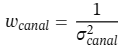
    3. Fusión Matricial: Multiplicas cada canal crudo por su respectivo peso normalizado antes de sumarlos.

In [53]:
r_glx_rgb_grm = make_lupton_rgb(image_r=image_data[2], image_g=image_data[1], image_b=image_data[0], stretch=.1)
r_glx_rgb_md4 = make_lupton_rgb(image_r=image_data[3], image_g=image_data[2], image_b=image_data[1], stretch=0.1)
r_glx_rgb_chn =image_data[0]+image_data[1] +image_data[2]+image_data[3]

luz_chn = np.median(r_glx_rgb_chn) + np.std(r_glx_rgb_chn)*2
luz_md4 = np.median(r_glx_rgb_md4) + np.std(r_glx_rgb_md4)*2
luz_grm = np.median(r_glx_rgb_grm) + np.std(r_glx_rgb_grm)*2

IndexError: index 3 is out of bounds for axis 0 with size 3

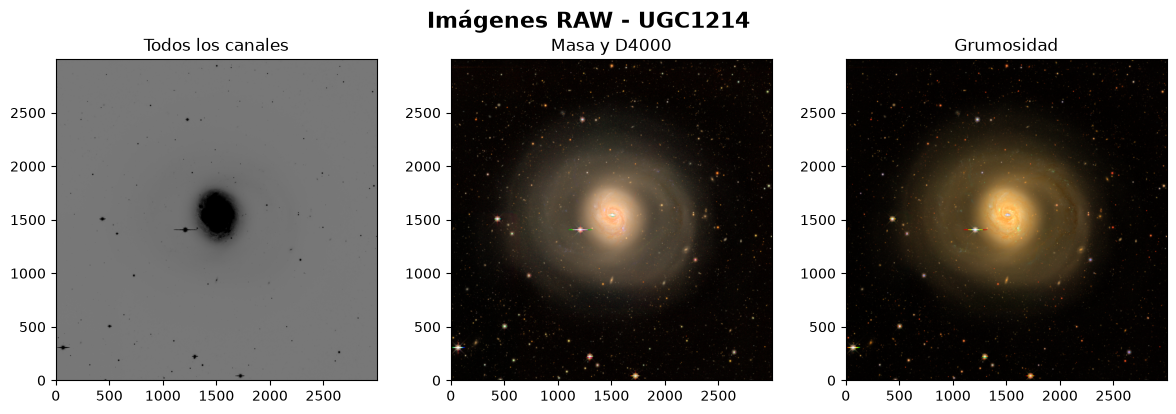

In [47]:
fig, axis = plt.subplots(nrows=1, ncols=3, figsize=(12,4))
fig.suptitle(f'Imágenes RAW - {gname.split("_")[0]}', fontsize=16, fontweight='bold')
for idx, ax in enumerate(axis):
    if idx==0:
        ax.imshow(r_glx_rgb_chn, vmin = np.min(r_glx_rgb_chn), vmax=luz_chn, origin='lower', cmap="Greys")
        ax.set_title('Todos los canales')
    elif idx==1:
        ax.imshow(r_glx_rgb_md4, vmin = np.min(r_glx_rgb_md4), vmax=luz_md4, origin='lower')
        ax.set_title('Masa y D4000')
    else:
        ax.imshow(r_glx_rgb_grm, vmin = np.min(r_glx_rgb_grm), vmax=luz_grm, origin='lower')
        ax.set_title('Grumosidad')
    ax.axis('on')

plt.tight_layout()
plt.show()

# Detección de la galaxia

## Estimación de métricas del background

### ¿Qué hace metricas_fondo?
- Modela y calcula el fondo del cielo astronómico parásito para su posterior sustracción.
- **El Fondo del Cielo (Sky Background)**: Es una contribución de luz no deseada, constante y suave provocada por la atmósfera terrestre, el polvo zodiacal o la contaminación lumínica. Eleva artificialmente el valor mínimo de todos tus píxeles.
- **El Ruido Estocástico (Sky Noise)**: Son las fluctuaciones aleatorias (el grano fotográfico o ruido de disparo de los fotones). Ningún estimador como Background2D elimina este grano; solo calcula el nivel medio de la neblina.

***La función metricas_fondo mide el nivel base del universo local para poder restarlo (Imagen - Fondo). Al restarlo, el espacio profundo promedia matemáticamente 0.0, pero el grano (ruido) sigue ahí.***

In [31]:
def metricas_fondo (arreglo):
    '''
    El objetivo de la función es poder detectar el valor de fondo para cada canal de las diferentes imágenes.
    Pipeline:
        1. Obtener el box_size que es dato más importante para calcular el los "bloques" en los que se va a analizar al imagen.
            1. Cálculo d ela mediana con sigma_clipped_stats
            2. Uso regionprops, sirve para hacer varios segmentos de la imagen
            3. Obtengo el valor de axis_major_length, esto lo obtengo del valor que tenga la area más grande.
            4. Calculo el tamaño del box size y filter; dejo un valor fijo de alpha 5, lo anterior basado en que si aplico un alpha de 4 ó 6 tendría box muy grande o muy pequeño, perdiendo propiedades de la galaxia
            NOTA: EL BOX_SIZE y el FILTER requieren ser números impares
        2. Cálculo del valor del fondo (cielo astronómico).
            1. Implemento photutils.background.Background2D para obtener el valor del cielo astronómico.
    Return Empaqueto todos los resultados de los arreglos son ruido, la mediana de sigma_clipped_stats, y los arreglos de los backgrounds
    '''
    for idx, arr in enumerate(arreglo):

        sc = SigmaClip(sigma=3.0)
        back_median = MedianBackground(sigma_clip=sc)

        #Métricas del cielo astronómico por canal
        _, sc_med, _ = sigma_clipped_stats(data=arr,sigma=3.5, maxiters=10)
        #obtengo el regionprops
        reg_props = regionprops(np.astype(arreglo,int))
        #obtención del tamaño del eje mas grande de una elipse que engloba la galaxia
        max_axis = [i.axis_major_length for i in reg_props if i.area == max([i.area for i in reg_props])][0] #resto 1 para tener el índice correcto, los labels están recorridos
        #tamaño box_size y filtros
        bs = int(np.round(max_axis / 5, 0))
        filters = int(np.round(2 * (bs / 20) + 1, 0))
        if bs %2 ==0: bs+=1
        if filters%2==0: filters +=1

        #cálculo del ruido por canal y recalculo los valores de los arreglos
        bkg = Background2D(arr, box_size=(bs, bs), filter_size=(filters, filters), 
                sigma_clip=sc, bkg_estimator=back_median, filter_threshold=sc_med)
        arr_cielo_canal = arr - bkg.background

        #guardo el valor por cada canal
        if idx==0:
            arr_cielo_g = arr_cielo_canal
            sc_g = sc_med
            bkg_g = bkg
        elif idx==1:
            arr_cielo_r = arr_cielo_canal
            sc_r = sc_med
            bkg_r = bkg
        elif idx==2:
            arr_cielo_i = arr_cielo_canal
            sc_i = sc_med
            bkg_i = bkg
        else:
            arr_cielo_z = arr_cielo_canal
            sc_z = sc_med
            bkg_z = bkg

    return {
        'g':{'cielo':arr_cielo_g, 'sc':sc_g, 'bkg':bkg_g},
        'r':{'cielo':arr_cielo_r, 'sc':sc_r, 'bkg':bkg_r},
        'i':{'cielo':arr_cielo_i, 'sc':sc_i, 'bkg':bkg_i},
        'z':{'cielo':arr_cielo_z, 'sc':sc_z, 'bkg':bkg_z},
    },{'box_size':bs, 'filters':filters}



In [32]:
bkg_canales, params_bkg = metricas_fondo(image_data)

## Tipos de matrices

Utilizaré 3 tipos de matrices:
1. Matriz de Lupton (Promedio Aritmético con Corrección de Cielo Local)
    - Física del Método: Se calcula aplicando el promedio aritmético pixel a pixel exclusivamente sobre los canales que ya han sido purificados de la neblina del cielo astronómico parásito en la función *metricas_fondo*.
    - Justificación: Al remover el nivel medio del fondo antes de promediar, los píxeles del espacio profundo se centran estadísticamente en \[0.0\]. Esto preserva la linealidad y los flujos relativos verdaderos entre las componentes ópticas e infrarrojas de la galaxia, sirviendo como la base óptima para el mapeo espectroscópico balanceado.
2. Matriz Estándar (Promedio Aritmético Crudo - Grupo de Control)
    - Física del Método: Se calcula **promediando** directamente los canales tal como vienen del archivo FITS original **(RAW Data)**, arrastrando de forma íntegra la neblina y la radiación de fondo del cielo de cada noche de observación.
    - Justificación de Ciencia de Datos: Funge como el **Grupo de Control Negativo**. Su función en el experimento es **demostrar de manera cuantitativa (mediante la pérdida de Entropía de Shannon) cómo el ruido instrumental degrada los gradientes morfológicos si no se aplica una etapa previa de sustracción de fondo**. 
3. Matriz Empírico-Estadística (Ponderación por Varianza Inversa)
    - Física del Método: Es una combinación lineal optimizada donde el peso (w) asignado a cada canal es inversamente proporcional a la **varianza** $$\sigma _{c}^{2}$$ de su ruido de fondo, asegurando la conservación del flujo mediante la normalización de la suma de pesos a \[1.0\]:
     $$w_{c}=\frac{1/\sigma _{c}^{2}}{\sum _{j}(1/\sigma _{j}^{2})}$$
    - Justificación: En imágenes de cielo profundo, frentes de onda como *la banda z son más ruidosas debido al grano térmico del detector*. Este método *castiga* de forma inteligente a las bandas sucias asignándoles una fracción *menor de peso*, y **premia a las bandas nítidas (como la g o r)**, maximizando analíticamente la relación señal-ruido global y limpiando el espacio profundo circundante de forma estocástica.

### Bibliografía: Colapso Multibanda

1. **Fundamento del Co-adicionado y Combinación Óptima:**  
   El estándar de la astrofísica profesional para combinar imágenes de múltiples filtros maximizando la relación señal-ruido mediante ponderación por varianza inversa está formalizado en el trabajo clásico de [White, R. L. (1999) en la Astronomical Society of the Pacific](https://harvard.edu "An Image Coaddition Strategy for Deep Surveys"). Este artículo detalla matemáticamente cómo la ponderación inversa a la dispersión del cielo evita la propagación del grano térmico de las bandas ruidosas hacia la matriz final combinada.
   
2. **Conservación de Flujos Relativos (Lupton):**  
   Los principios de preservación fotométrica y álgebra matricial para construir imágenes multibanda balanceadas sin inducir gradientes artificiales en galaxias densas provienen del desarrollo del pipeline de SDSS por [Lupton, R., et al. (2004) en The Astronomical Journal](https://iopsetting.com "Preparing Red-Green-Blue Images from CCD Data"). La publicación valida por qué la sustracción local previa del cielo es mandatoria antes de cualquier colapso lineal.

3. **Mapeo de Datos en el DESI Legacy Imaging Surveys:**  
   La justificación de utilizar el promedio por flujos y matrices de peso basadas en el ruido instrumental para procesar los datos de las bandas `griz` del cartografiado que alimenta esta tesis se encuentra detallada en el paper oficial del consorcio: [Dey, A., et al. (2019). Overview of the DESI Legacy Imaging Surveys. *The Astronomical Journal*](https://iop.org "Overview of the DESI Legacy Imaging Surveys").


### Referencias de Soporte Metodológico para el Colapso Multibanda

1. **Fundamento del Co-adicionado y Combinación Ponderada (PENDIENTE DE VALIDAR LIGA):**  
   El estándar astrofísico e histórico para la combinación de imágenes multiepoca o multifiltro maximizando la relación señal-ruido mediante la propagación estadística de pesos inversos a la varianza está documentado formalmente a través del sistema de la NASA/Harvard en: [White, R. L. (1999). Post-COADD Matched Filtering. *Astronomical Data Analysis Software and Systems VIII*, ASP Conference Series, Vol. 172](https://harvard.edu "Post-COADD Matched Filtering — NASA/ADS"). El texto técnico valida matemáticamente cómo la adición ponderada por el grano del cielo evita la dispersión del ruido instrumental sobre los perfiles de baja señal.
   
2. **Conservación de Flujos Relativos (Lupton):**  
   Los principios de preservación fotométrica y álgebra matricial para construir imágenes multibanda balanceadas sin inducir gradientes artificiales en galaxias densas provienen del desarrollo del pipeline de SDSS por [Lupton, R., et al. (2004). Preparing Red-Green-Blue Images from CCD Data. *The Astronomical Journal*, 127(6)](https://harvard.edu "Preparing Red-Green-Blue Images from CCD Data — NASA/ADS"). La publicación valida por qué la sustracción local previa del cielo es mandatoria antes de cualquier colapso lineal.

3. **Mapeo de Datos en el DESI Legacy Imaging Surveys:**  
   La especificación técnica de utilizar el promedio por flujos y matrices de peso basadas en el ruido instrumental para procesar los datos de las bandas `griz` del cartografiado exacto de esta tesis se encuentra detallada en: [Dey, A., et al. (2019). Overview of the DESI Legacy Imaging Surveys. *The Astronomical Journal*, 157(5)](https://harvard.edu "Overview of the DESI Legacy Imaging Surveys — NASA/ADS").


In [9]:
def matrices_colapso(arreglos_limpios, bkg_params, img_data):
    '''
    Descripción del pipeline:

    Son 3 inputs:
        - los arrgelos de background canales
        - el tamaño del box_size y filter_size
        - el arreglo RAW

    1. Calcular la matriz de lupton y su background
    2. Calcular la matríz estándar
    3. Calcular la matriz estadística
    4. Diccionario con los 3 tipos de matrices
    
    Return diccionario de matrices y las métricas del fondo colapsado (rms y mediana)
    
    '''
    glx_lupton= np.stack(
        (
            arreglos_limpios['g']['cielo'],
            arreglos_limpios['r']['cielo'],
            arreglos_limpios['i']['cielo'],
            arreglos_limpios['z']['cielo']
        )
        ,axis=0)

    glx_lupton = np.mean(glx_lupton, axis=0)

    _, _, std = sigma_clipped_stats(glx_lupton, sigma=3, maxiters=10)
    sc = SigmaClip(sigma=3.0)

    bkg = Background2D(
        glx_lupton, 
        box_size=(bkg_params['box_size'], 
        bkg_params['box_size']),
        filter_size=(bkg_params['filters'],
        bkg_params['filters']), 
        sigma_clip=sc, 
        bkg_estimator=MedianBackground(sigma_clip=sc), 
        filter_threshold=std*3
    )
    
    #proceso de Estándar
    glx_estandar = np.mean(img_data, axis=0)
    #Cálculo de la galaxia estadística
    for k,v in arreglos_limpios.items():
        if k=='g':
            norm_g = 1/(v['bkg'].background_rms**2 + 1e-10)
            canal_g = v['cielo']
        elif k=='r':
            norm_r = 1/(v['bkg'].background_rms**2+ 1e-10)
            canal_r = v['cielo']
        elif k=='i':
            norm_i = 1/(v['bkg'].background_rms**2+ 1e-10)
            canal_i = v['cielo']
        else:
            norm_z = 1/(v['bkg'].background_rms**2+ 1e-10)
            canal_z = v['cielo']
    #pondero los rms 
    sum_rms = norm_g + norm_r + norm_i + norm_z
    glx_estadistica = (canal_g * (norm_g/sum_rms)) + (canal_r * (norm_r/sum_rms)) + (canal_i * (norm_i/sum_rms)) + (canal_z * (norm_z/sum_rms))

    dict_glx = {'Lupton': glx_lupton, 'Estandar': glx_estandar, 'Estadistica': glx_estadistica}
    return dict_glx, bkg.background_rms, bkg.background_median

In [33]:
glx_dict, rms_bkg, med_bkg = matrices_colapso(bkg_canales, params_bkg, image_data)

## Normalización temporal para obtener la máscara gaussina

In [11]:
def norm_temp (glx_colapsada):
    '''
    El objetivo de esto es sólo poner los valores del arreglo en un rango entre 0 y 1
    '''

    aprint = AsymmetricPercentileInterval(lower_percentile=5, upper_percentile=99.5) #el punto es que los outliers bajen su escala en un 0.5%
    strech = AsinhStretch(a=0.1) # redistribuye todos los datos a una escala entre 0 y 1
    img_norm = ImageNormalize(data=glx_colapsada, interval=aprint, stretch=strech)

    return img_norm(glx_colapsada).data
    


In [34]:
glx_norm = norm_temp(glx_dict['Lupton'])

## Máscara Gaussiana

In [13]:
def mascara_gaussiana(arreglo, bkg, sigma):
    '''
    Descripción del pipeline:
    1. Obtener la segmentación gaussina para separar la galaxia y las estrellas
    2. Elaborar la máscara booleana de las estrellas de campo
    3. Generar la máscara final con la galaxia del tamaño total
    Return el boolean mask, y el seg_gaus
    '''
    ## PASO 1:
    #instancio los Kernels
    g2dK=Gaussian2DKernel(x_stddev=5, y_stddev=5)
    #convolusionamos la data
    convolve_Gauss = convolve(arreglo, g2dK)

    umbral_i = detect_threshold(convolve_Gauss, n_sigma=sigma, error=bkg)
    #segmento la imágen
    seg_gauss_i = detect_sources(data=convolve_Gauss, threshold=umbral_i, n_pixels=5, connectivity=8)
    
    ##PASO 2:
    # Quedarnos sólo con la imagen el centro
    # 1. Obetner los descriptores geométricos de cada segmentación de la imagen
    segments = regionprops(label_image=seg_gauss_i.data)
    #2. Extraer la propieadad coords para ubicar cada una de las coordenadas en un acomprehension list
    # Dinamicé el centro de la imagen, así ya sin importar el W/H simepre busca el centro por defecto
    cl_coords = [(s.label, np.sqrt((s.centroid[0]- np.round(headers['IMAGEH']/2,0))**2 +(s.centroid[1]-np.round(headers['IMAGEW']/2,0))**2 )) for s in segments] # corregir el cálculo del centroide
    #3. obtener el valor mínimo de de la comprehensión list, esto porque es el que tiene la menor distancia del centro del imagen
    id_galaxia=min(cl_coords, key= lambda dist:dist[1])
    bm_galaxia = seg_gauss_i.data == id_galaxia[0]
    bm_estrellas = (seg_gauss_i.data > 0) & (seg_gauss_i.data != id_galaxia[0])

    return bm_galaxia, seg_gauss_i, bm_estrellas

In [38]:
mascara = mascara_gaussiana(glx_dict['Lupton'], np.mean(rms_bkg), sigma=1)

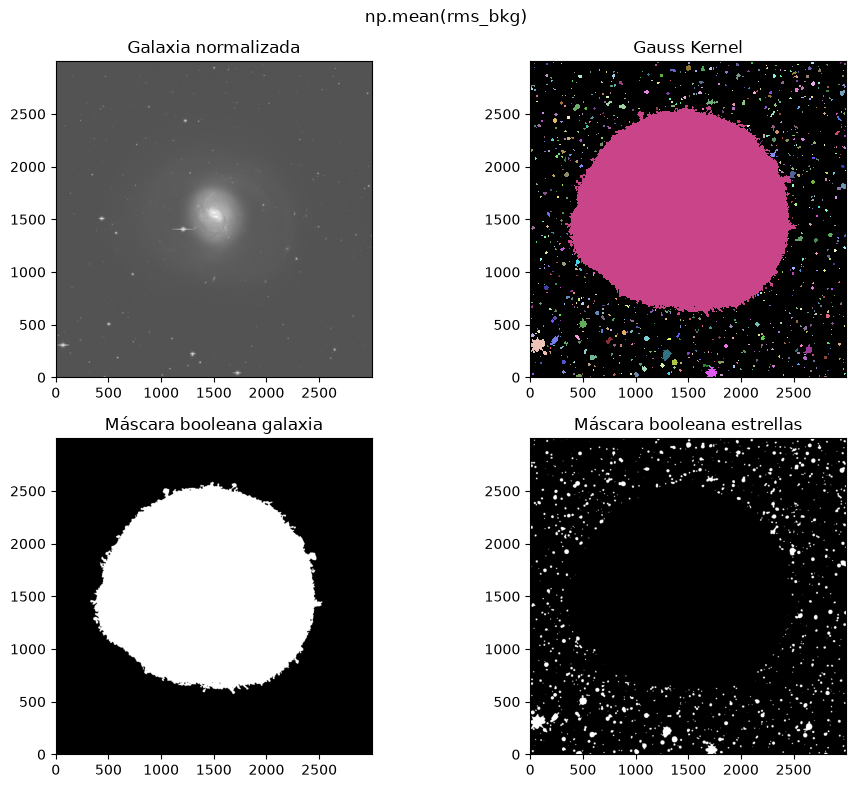

In [39]:
#grafico la segmentación de la galaxia
fig, axs = plt.subplots(nrows=2,ncols=2,figsize=(10,8))
axs[0,0].imshow(glx_norm, origin='lower', cmap='grey')
axs[0,0].set_title('Galaxia normalizada')
mascara[1].imshow(ax=axs[0,1])
axs[0,1].set_title('Gauss Kernel')
axs[1,0].imshow(mascara[0], cmap='grey', origin='lower')
axs[1,0].set_title('Máscara booleana galaxia')
axs[1,1].imshow(mascara[2], cmap='grey', origin='lower')
axs[1,1].set_title('Máscara booleana estrellas')
plt.suptitle('np.mean(rms_bkg)')
plt.tight_layout()
plt.show()

# Image segmentation - Spline

In [16]:
def spline (glx, mask):
    '''
    Descripción del pipeline:
    1. Cálculo de normalizaciones de todos los canales para obtener un sólo dato
    2. Se aplica inverse_gaussian_gradient para poder delimitar los bordes de la galaxia sumando todos los canales
    3. Otener el arreglo del spline con morphological_geodesic_active_contour
    4. Se obtiene la máscara binanria
    RETURN spline y máscara binaria, y normalización

    NOTA: SÓLO AL PASO 1 SE APLICA A LOS 3 CANALES, EL RESTO DE LOS PASOS SÓLO SE APLICA A UN SOLO CANAL, POR DEFAULT SERÁ UV
    '''
    
    #PASO 2
    arr_invgaus = inverse_gaussian_gradient(image=glx)
    #PASO 3
    snk_MGAC = morphological_geodesic_active_contour(
        gimage=arr_invgaus,
        num_iter=10,
        init_level_set=mask,
        threshold=0.1,
        balloon=0.2,
        smoothing=2,
    )
    #PASO 4
    mask_snk=ndimage.binary_fill_holes(snk_MGAC)
    mask_nn = mask_snk.astype(np.float32) # máscara para la neural network
    mask_cont = mask_snk.astype(np.int8) # spline para graficar

    return {
        #'glx':glx_norm,
        #'norms': minmax_norm,
        'inverse_gausse': arr_invgaus,
        'snk_mgac': snk_MGAC,
        'mask_nn':mask_nn,
        'mask_cont':mask_cont
    }

In [36]:
glx_final = spline(glx_dict['Lupton'], mascara[0])

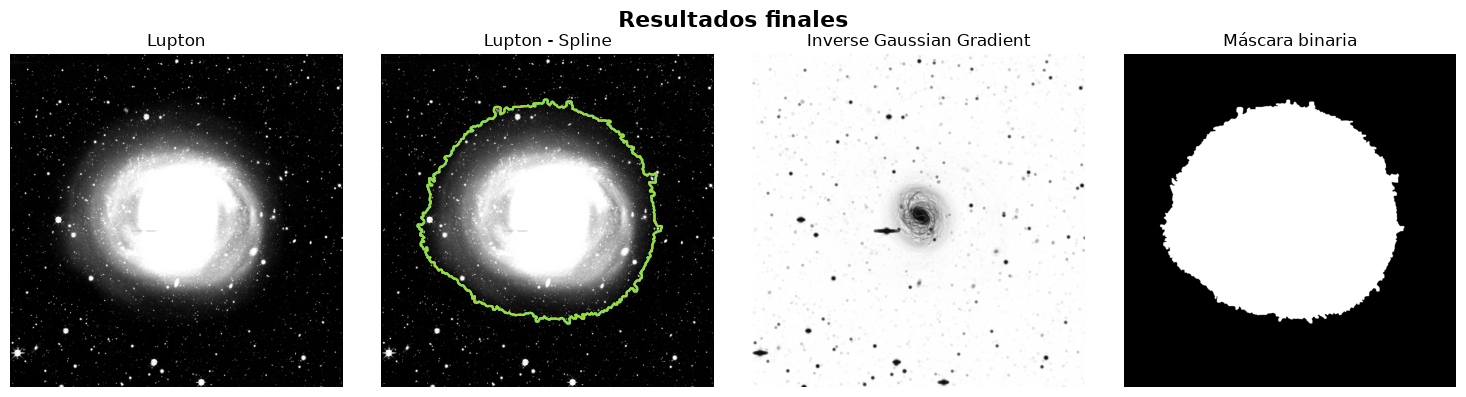

In [37]:
fig, axs = plt.subplots(nrows=1,ncols=4,figsize=(15,4))
fig.suptitle('Resultados finales', fontsize=16, fontweight='bold')
axs[0].imshow(glx_dict['Lupton'], origin='lower', cmap='grey', vmin= np.median(glx_dict['Lupton']), vmax = np.mean(glx_dict['Lupton']))
axs[0].set_title('Lupton')
axs[0].axis('off')
axs[1].imshow(glx_dict['Lupton'], origin='lower', cmap='grey' , vmin= np.median(glx_dict['Lupton']), vmax = np.mean(glx_dict['Lupton']))
axs[1].contour(glx_final['mask_cont'])
axs[1].set_title('Lupton - Spline')
axs[1].axis('off')
axs[2].imshow(glx_final['inverse_gausse'], cmap='grey', origin='lower' )
axs[2].set_title('Inverse Gaussian Gradient')
axs[2].axis('off')
axs[3].imshow(glx_final['mask_cont'], origin='lower', cmap='grey')
axs[3].set_title('Máscara binaria')
axs[3].axis('off')
plt.tight_layout()
plt.show()


# Prueba de generalización FITS

In [ ]:
fits_files=os.listdir(Path.cwd()/Path('Imagenes-Test'))
fits_path = Path.cwd()/Path('Imagenes-Test')
for f in fits_files:
    pf = fits_path/Path(f)
    if f.split(".")[-1]=='fits':
        # extracción del ID de la galaxia
        gname=f.split(sep="_")[0]

        # extracción de datos del archivo fits
        hdulist= fits.open(pf)
        headers = fits.getheader(pf)
        image_data= fits.getdata(pf)
        hdulist.close()

        if headers['BANDS   ']=='griz' or headers['BANDS']=='griz    ':
            #creación de folder
            pdir = Path(f'{fits_path}\{gname}')
            if not os.path.exists(pdir): os.mkdir(pdir)

            # graficas RAW
            r_glx_rgb_grm = make_lupton_rgb(image_r=image_data[2], image_g=image_data[1], image_b=image_data[0], stretch=.1)
            r_glx_rgb_md4 = make_lupton_rgb(image_r=image_data[3], image_g=image_data[2], image_b=image_data[1], stretch=0.1)
            r_glx_rgb_chn =image_data[0]+image_data[1] +image_data[2]+image_data[3]
            luz_chn = np.median(r_glx_rgb_chn) + np.std(r_glx_rgb_chn)*2
            luz_md4 = np.median(r_glx_rgb_md4) + np.std(r_glx_rgb_md4)*2
            luz_grm = np.median(r_glx_rgb_grm) + np.std(r_glx_rgb_grm)*2

            fig, axis = plt.subplots(nrows=1, ncols=3, figsize=(12,4))
            fig.suptitle(f'Imágenes RAW - {gname}', fontsize=16, fontweight='bold')
            for idx, ax in enumerate(axis):
                if idx==0:
                    ax.imshow(r_glx_rgb_chn, vmin = np.min(r_glx_rgb_chn), vmax=luz_chn, origin='lower', cmap="Greys")
                    ax.set_title('Todos los canales')
                elif idx==1:
                    ax.imshow(r_glx_rgb_md4, vmin = np.min(r_glx_rgb_md4), vmax=luz_md4, origin='lower')
                    ax.set_title('Masa y D4000')
                else:
                    ax.imshow(r_glx_rgb_grm, vmin = np.min(r_glx_rgb_grm), vmax=luz_grm, origin='lower')
                    ax.set_title('Grumosidad')
                ax.axis('off')
            plt.tight_layout()
            plt.savefig(fname=f'{pdir}/RAW_IMG_{gname}.jpg',dpi=300, bbox_inches='tight')
            plt.close(fig)

            #invocación de funciones
            bkg_canales, params_bkg = metricas_fondo(image_data)
            glx_dict, rms_bkg, med_bkg = matrices_colapso(bkg_canales, params_bkg, image_data)
            glx_norm = norm_temp(glx_dict['Lupton'])
            mascara = mascara_gaussiana(glx_dict['Lupton'], np.mean(rms_bkg), sigma=1)
            glx_final = spline(glx_dict['Lupton'], mascara[0])

            #graficas de máscaras
            fig, axs = plt.subplots(nrows=2,ncols=2,figsize=(10,8))
            axs[0,0].imshow(glx_norm, origin='lower', cmap='grey')
            axs[0,0].set_title('Galaxia normalizada')
            axs[0,0].axis('off')
            mascara[1].imshow(ax=axs[0,1])
            axs[0,1].set_title('Gauss Kernel')
            axs[0,1].axis('off')
            axs[1,0].imshow(mascara[0], cmap='grey', origin='lower')
            axs[1,0].set_title('Máscara booleana galaxia')
            axs[1,0].axis('off')
            axs[1,1].imshow(mascara[2], cmap='grey', origin='lower')
            axs[1,1].set_title('Máscara booleana estrellas')
            axs[1,1].axis('off')
            plt.tight_layout()
            plt.savefig(fname=f'{pdir}/Mascaras_{gname}.jpg',dpi=300, bbox_inches='tight')
            plt.close(fig)

            #IMAGE SEGMENTATION
            fig, axs = plt.subplots(nrows=1,ncols=4,figsize=(15,4))
            fig.suptitle('Resultados finales', fontsize=16, fontweight='bold')
            axs[0].imshow(glx_dict['Lupton'], origin='lower', cmap='grey', vmin= np.median(glx_dict['Lupton']), vmax = np.mean(glx_dict['Lupton']))
            axs[0].set_title('Lupton')
            axs[0].axis('off')
            axs[1].imshow(glx_dict['Lupton'], origin='lower', cmap='grey' , vmin= np.median(glx_dict['Lupton']), vmax = np.mean(glx_dict['Lupton']))
            axs[1].contour(glx_final['mask_cont'])
            axs[1].set_title('Lupton - Spline')
            axs[1].axis('off')
            axs[2].imshow(glx_final['inverse_gausse'], cmap='grey', origin='lower' )
            axs[2].set_title('Inverse Gaussian Gradient')
            axs[2].axis('off')
            axs[3].imshow(glx_final['mask_cont'], origin='lower', cmap='grey')
            axs[3].set_title('Máscara binaria')
            axs[3].axis('off')
            plt.tight_layout()
            plt.savefig(fname=f'{pdir}/img_seg_{gname}.jpg',dpi=300, bbox_inches='tight')
            plt.close(fig)
